# DDNN comparative analysis — 2015–2020 vs 2020–2026

Comparison of the distributional deep neural network of Marcjasz, Narajewski, Weron & Ziel (2022)
on the original window (**2015-01-01 → 2020-12-31**) and an updated window
(**2020-11-19 → 2026-11-19**), each 2,192 days, evaluated **separately** with the same protocol.

This notebook **does not train anything**. It reads

* `Datasets/DE_dataset_2015-2020.csv`, `Datasets/DE_dataset_2020-2026.csv`
* `Results/<RESULTS_TAG>/aggregated_ddnn_comparison.pkl`, written by `run_comparative_experiments.py`
  (set `RESULTS_TAG` below, or the environment variable `DDNN_RESULTS_TAG`).

**Models:** `naive`, `DNN-1/2` → `DNN-Ens`, `DNN-QRA`; `DDNN-JSU-1/2` → `DDNN-JSU-pEns`, `DDNN-JSU-qEns`;
optionally `LEAR-56/84/1092/1456` → `LEAR-Ens`, `LEAR-QRA` when the run includes LEAR.

**Splits (both horizons):** 1,092 training days → 364 validation days (in-sample = 1,456 days) →
182 QRA calibration days → 554 test days.

**Set-up:** hyper-parameters and input selections are the best trials of runs 1–2 of the paper's Optuna
studies (`trialfiles/`), re-used unchanged on both horizons (no re-tuning). Section 0 lists the run settings,
the convergence diagnostics of every network fit and the limitations of the protocol — read it first.

In [1]:
import os
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

ROOT = Path.cwd()
RESULTS_TAG = os.environ.get("DDNN_RESULTS_TAG", "neural_w7")        # folder under Results/
RESULTS_PATH = ROOT / "Results" / RESULTS_TAG / "aggregated_ddnn_comparison.pkl"
if not RESULTS_PATH.exists():
    available = sorted(p.parent.name for p in (ROOT / "Results").glob("*/aggregated_ddnn_comparison.pkl"))
    raise FileNotFoundError(f"{RESULTS_PATH} not found - run run_comparative_experiments.py first. "
                            f"Tags with results: {available}")
DATA = {"2015-2020": ROOT / "Datasets" / "DE_dataset_2015-2020.csv",
        "2020-2026": ROOT / "Datasets" / "DE_dataset_2020-2026.csv"}

with open(RESULTS_PATH, "rb") as fh:
    R = pickle.load(fh)
META, H = R["meta"], R["horizons"]
MODELS, RUNS = META["models"], META["runs"]
HAS_LEAR = "LEAR" in META["groups"]
frames = {h: pd.read_csv(p, index_col=0, parse_dates=True) for h, p in DATA.items()}

print(f"Results : {RESULTS_PATH.relative_to(ROOT)}  (created {META['created']}, tag = {META['settings']['tag']})")
print(f"Models  : {META['groups']}")
if META["settings"].get("debug"):
    print("WARNING: debug artifact - sparse retraining / few epochs, numbers are NOT meaningful.")
for h, df in frames.items():
    print(f"{h}: {df.index[0]} -> {df.index[-1]}  ({len(df):,} rows)")

Results : Results\neural_w7\aggregated_ddnn_comparison.pkl  (created 2026-11-22T17:17:10, tag = neural_w7)
Models  : ['DNN', 'DDNN-JSU']
2015-2020: 2015-01-01 00:00:00 -> 2020-12-31 23:00:00  (52,608 rows)
2020-2026: 2020-11-19 00:00:00 -> 2026-11-19 23:00:00  (52,608 rows)


In [2]:
# ---- shared style (reference palette: categorical slots, blue sequential ramp) ----
C_HOR = {"2015-2020": "#2a78d6", "2020-2026": "#eb6834"}          # slot 1 / slot 2
C_FUEL = {"API2_Coal": "#2a78d6", "Brent_oil": "#eb6834", "TTF_Gas": "#1baf7a"}
C_BENCH = {"LEAR-QRA": "#2a78d6", "DNN-QRA": "#1baf7a"}
C_MODEL = {"DNN-1": "#1baf7a", "DNN-2": "#0f7a55", "DDNN-JSU-1": "#6250d6", "DDNN-JSU-2": "#e34948"}
PI_FILL = {98: "#cde2fb", 90: "#86b6ef", 50: "#2a78d6"}             # sequential blue, light -> dark
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
OVERLAP = (pd.Timestamp("2020-11-19"), pd.Timestamp("2020-12-31 23:00"))
LABEL = {"2015-2020": "2015–2020", "2020-2026": "2020–2026"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "font.size": 9,
    "lines.linewidth": 1.0,
})

def boundaries(h):
    s = H[h]["splits"]
    return [("Validation", s["val_start"]), ("QRA calibration", s["qra_start"]), ("Out-of-sample test", s["test_start"])]

print(pd.DataFrame({h: {k: v.date() for k, v in H[h]["splits"].items()} for h in H}))

              2015-2020   2020-2026
train_start  2015-01-01  2020-11-19
val_start    2017-12-28  2023-11-16
qra_start    2018-12-27  2024-11-14
test_start   2019-06-27  2025-05-15
end          2020-12-31  2026-11-19


## 0. Run settings, convergence & limitations

**How to read the results.** Each network is re-trained every `retrain_every` days on the trailing
1,449 usable days (early stopping on a random 20 % split) and its weights are reused for the following
days with fresh daily inputs. A fit is *converged* when early stopping triggered before the epoch limit;
fits that **hit the limit** were still improving and make the run under-trained. The gap between run 1
and run 2 of the same family is the noise floor of the comparison.

In [3]:
s = META["settings"]
print(f"NN re-fit every {s['retrain_every']} d | max epochs {s['epochs']} (patience {s['patience']}) | "
      f"QRA re-fit every {s['qra_refit_every']} d | LEAR: {'on, ' + s['lear_method'] if HAS_LEAR else 'off'} | "
      f"{s['n_jobs']} workers x {s['tf_threads']} thread")

diag = pd.concat([H[h]["fit_diagnostics"].assign(horizon=LABEL[h]) for h in H], ignore_index=True)
conv = diag.groupby(["horizon", "model"]).agg(
    fits=("epochs", "size"), epochs_median=("epochs", "median"),
    epochs_p90=("epochs", lambda x: x.quantile(0.9)), best_epoch_median=("best_epoch", "median"),
    hit_epoch_cap=("hit_cap", "mean"), best_val_loss_median=("best_val_loss", "median"),
    minutes_per_fit=("seconds", lambda x: x.mean() / 60))
share = diag["hit_cap"].mean()
print(f"Fits that hit the epoch limit: {share:.1%} of {len(diag)} -> "
      + ("OK, all fits converged by early stopping." if share == 0 else
         "UNDER-TRAINED fits present - treat the affected models with caution."))
conv.style.format({"epochs_median": "{:.0f}", "epochs_p90": "{:.0f}", "best_epoch_median": "{:.0f}",
                   "hit_epoch_cap": "{:.0%}", "best_val_loss_median": "{:.3f}", "minutes_per_fit": "{:.1f}"})

NN re-fit every 7 d | max epochs 1500 (patience 50) | QRA re-fit every 1 d | LEAR: off | 4 workers x 1 thread
Fits that hit the epoch limit: 0.0% of 744 -> OK, all fits converged by early stopping.


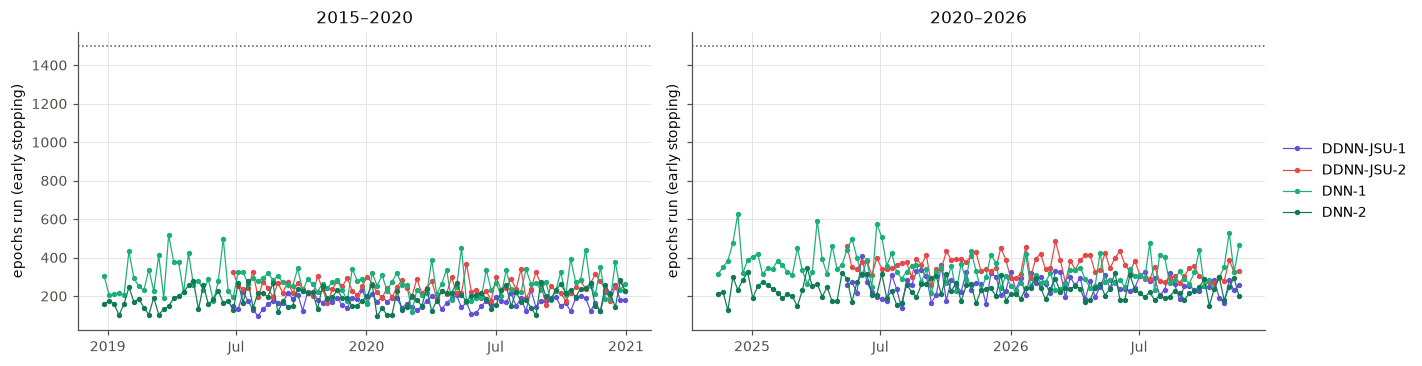

In [4]:
# stopping epoch of every fit over time (one point per weekly re-fit)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for ax, h in zip(axes, H):
    d = H[h]["fit_diagnostics"]
    for m, g in d.groupby("model"):
        ax.plot(g["fit_date"], g["epochs"], marker="o", ms=2.5, lw=0.8, color=C_MODEL.get(m, MUTED), label=m)
    ax.axhline(s["epochs"], color=MUTED, ls=":", lw=1)
    loc = mdates.AutoDateLocator(maxticks=7)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))
    ax.set_title(LABEL[h])
    ax.set_ylabel("epochs run (early stopping)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

In [5]:
# noise floor: gap between the two runs of each family (test period)
rows = []
for h in H:
    mt = H[h]["metrics_table"]
    for fam, metric in (("DNN", "MAE"), ("DDNN-JSU", "CRPS")):
        names = [f"{fam}-{r}" for r in RUNS]
        if all(n in mt.index for n in names):
            v = mt.loc[names, metric].to_numpy(dtype=float)
            rows.append({"horizon": LABEL[h], "family": fam, "metric": metric,
                         **{n: x for n, x in zip(names, v)}, "gap (% of mean)": 100 * abs(v[0] - v[1]) / v.mean()})
pd.DataFrame(rows).set_index(["horizon", "family"]).style.format(precision=2)

In [6]:
print("Limitations of this protocol:")
for i, t in enumerate(META["limitations"], 1):
    print(f"{i}. {t}")

Limitations of this protocol:
1. Hyper-parameters and input selections are the paper's best Optuna trials (runs 1-2 of 4), tuned on 2015-2018 with the buggy features of the published code; re-used unchanged on both horizons. 2015-2020 is therefore evaluated with settings tuned on its own in-sample period, 2020-2026 is not.
2. Neural networks are re-trained every `retrain_every` days (paper: daily); weights are reused in between, with daily inference on fresh features. Adaptation to abrupt regime changes is understated.
3. Ensembles average 2 runs instead of 4, so pEns/qEns gain less from diversity than in the paper.
4. Training is stochastic (random 20 % early-stopping split, weight init): the gap between run 1 and run 2 is the noise floor - differences smaller than that are not findings.
5. Price levels and volatility differ strongly between the two test periods (2019-06 -> 2020-12 incl. COVID vs 2025-05 -> 2026-11 with frequent negative prices): compare horizons only through relative

## 1. Feature & regime overview (adaptation of Figure 2)

Both datasets on one continuous time axis, 2015-01-01 → 2026-11-19. The grey band is the
43-day overlap (2020-11-19 → 2020-12-31), where both series are drawn. Dashed lines mark the
start of validation, QRA calibration and out-of-sample testing for each horizon (horizon colour).

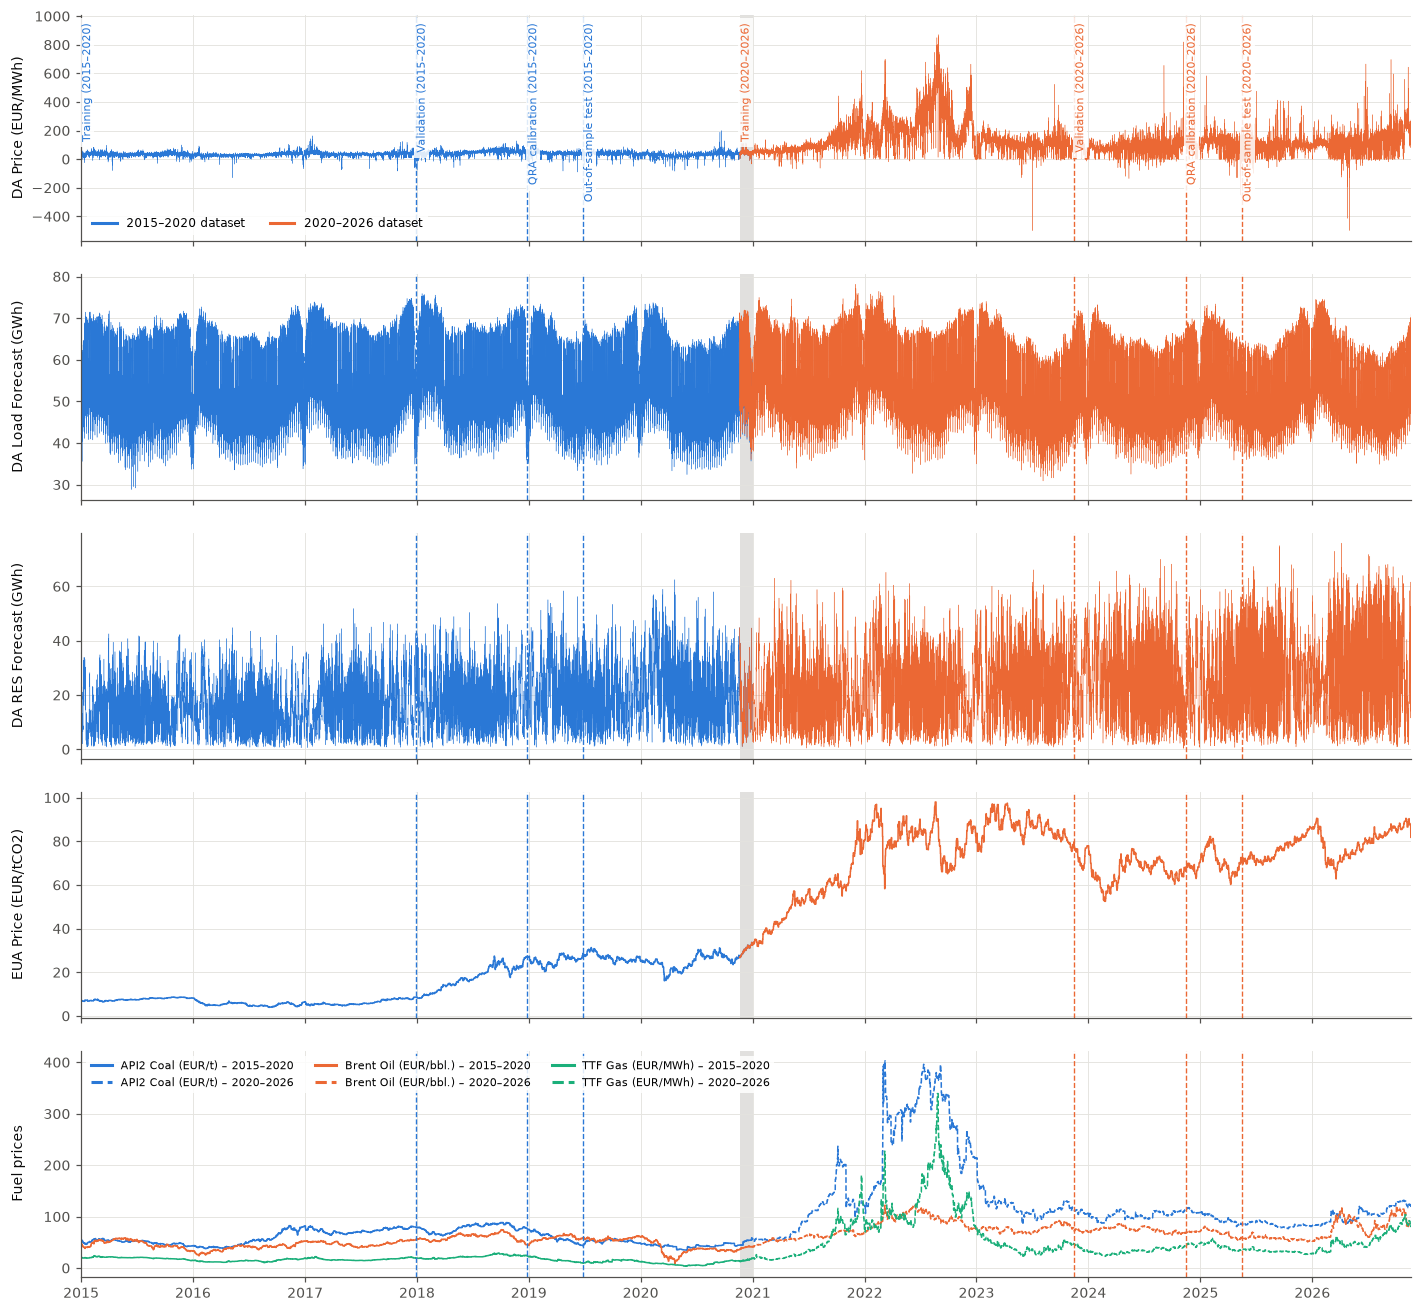

In [7]:
PANELS = [("Price", "DA Price (EUR/MWh)", 1.0),
          ("Load_DA_Forecast", "DA Load Forecast (GWh)", 1e-3),
          ("Renewables_DA_Forecast", "DA RES Forecast (GWh)", 1e-3),
          ("EUA", "EUA Price (EUR/tCO2)", 1.0)]
FUELS = [("API2_Coal", "API2 Coal (EUR/t)"), ("Brent_oil", "Brent Oil (EUR/bbl.)"), ("TTF_Gas", "TTF Gas (EUR/MWh)")]

def overview(start=None, end=None, hourly_lw=0.25):
    fig, axes = plt.subplots(5, 1, figsize=(13, 12), sharex=True)
    for ax, (col, label, k) in zip(axes, PANELS):
        for h, df in frames.items():
            s_ = df[col].loc[start:end] * k
            ax.plot(s_.index, s_.values, color=C_HOR[h], lw=hourly_lw if col != "EUA" else 1.0,
                    label=f"{LABEL[h]} dataset")
        ax.set_ylabel(label)
    ax = axes[4]
    for col, label in FUELS:
        for h, df in frames.items():
            s_ = df[col].loc[start:end]
            ax.plot(s_.index, s_.values, color=C_FUEL[col], lw=1.0, ls="-" if h == "2015-2020" else "--",
                    label=f"{label} – {LABEL[h]}")
    ax.set_ylabel("Fuel prices")
    lo = pd.Timestamp(start) if start else min(df.index[0] for df in frames.values())
    hi = pd.Timestamp(end) if end else max(df.index[-1] for df in frames.values())
    inside = lambda d: lo <= d <= hi                                   # noqa: E731
    for ax in axes:
        ax.axvspan(*OVERLAP, color="#bdbcb6", alpha=0.45, lw=0)
        for h in H:
            for name, d in boundaries(h):
                if inside(d):
                    ax.axvline(d, color=C_HOR[h], ls="--", lw=0.9)
        ax.set_xlim(lo, hi)
    top = axes[0]
    for h in H:
        for name, d in [("Training", H[h]["splits"]["train_start"])] + boundaries(h):
            if inside(d):
                top.text(d, 0.98, f" {name} ({LABEL[h]}) ", rotation=90, va="top", ha="left", fontsize=7,
                         color=C_HOR[h], transform=top.get_xaxis_transform(),
                         bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1))
    for ax, ncols, size, loc in ((axes[0], 2, 8, "lower left"), (axes[4], 3, 7, "upper left")):
        leg = ax.legend(loc=loc, ncols=ncols, fontsize=size, frameon=True, facecolor="white",
                        edgecolor="none", framealpha=0.85)
        for line in leg.get_lines():
            line.set_linewidth(2)
    if start is None:
        axes[-1].xaxis.set_major_locator(mdates.YearLocator())
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    else:
        axes[-1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0))
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
    fig.align_ylabels(axes)
    fig.tight_layout()
    return fig

fig = overview()
plt.show()

### 1b. Zoom on the overlap window

Both datasets drawn over the 43 overlap days (±3 weeks). Price and the daily commodity series are
identical on the shared days; load differs by ~1 % (2015–2020 power data come from `DE.csv`,
2020–2026 from SMARD).

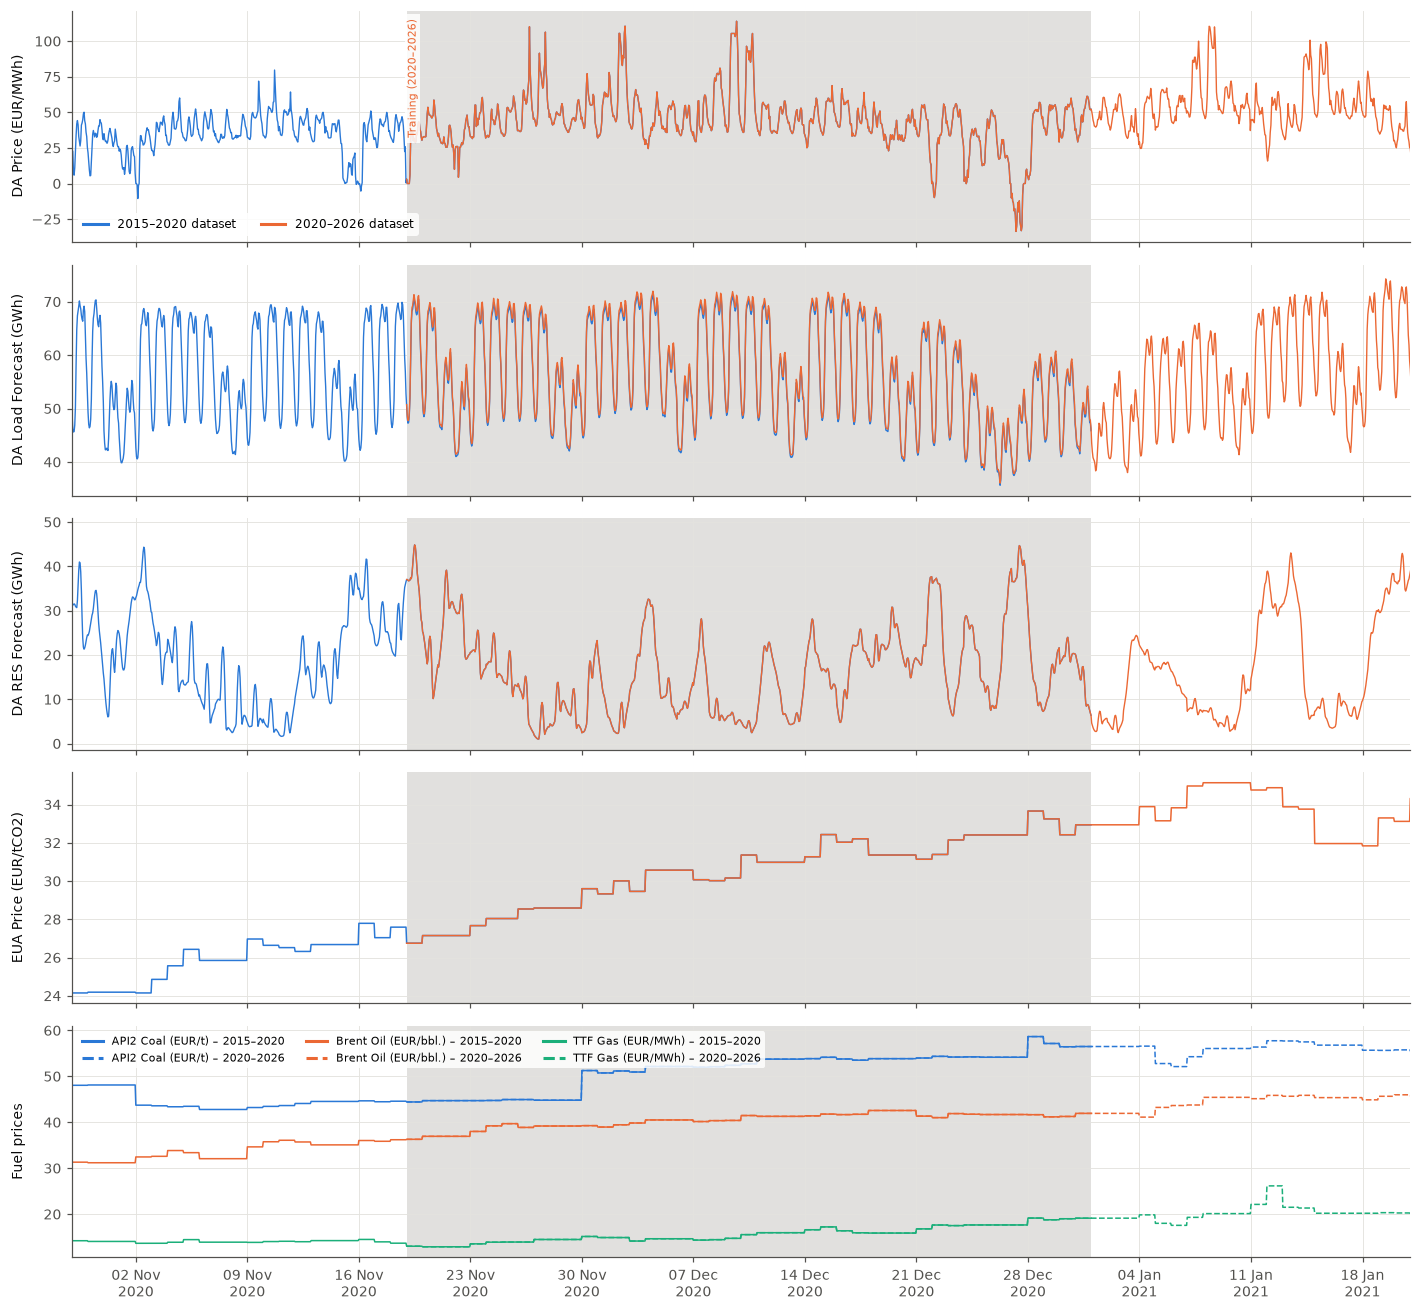

In [8]:
fig = overview("2020-10-29", "2021-01-21", hourly_lw=0.9)
plt.show()

## 2. In-sample price distributions & fitted densities (adaptation of Figure 3)

In-sample = first 1,456 days of each horizon (training + validation):
**2015–2018** = 2015-01-01 → 2018-12-26, **2020–2024** = 2020-11-19 → 2024-11-13.
Normal and Johnson's SU densities are fitted by maximum likelihood for each era and hour.
Histograms are clipped to the 0.5–99.5 % range of the pooled data for readability (fits use all points).

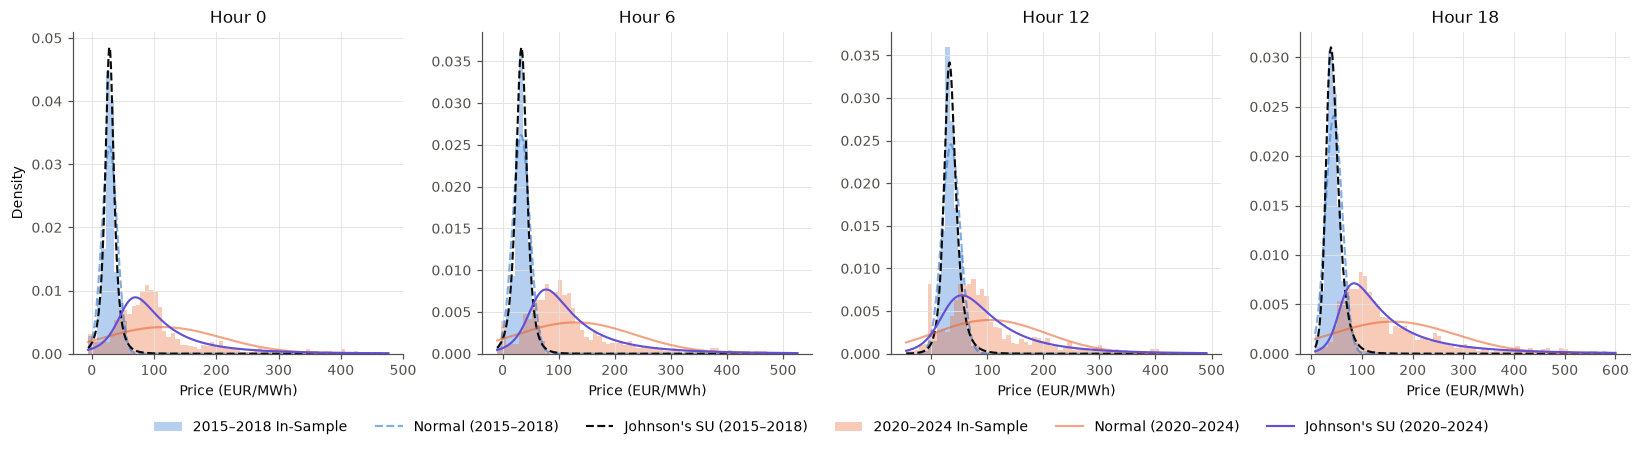

In [9]:
HOURS = [0, 6, 12, 18]
ERA = {"2015-2020": "2015–2018", "2020-2026": "2020–2024"}
N_IN = META["windows"]["N_INSAMPLE"]
insample = {h: frames[h]["Price"].to_numpy()[: N_IN * 24].reshape(N_IN, 24) for h in frames}

fits, fig, axes = [], *plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
for ax, hr in zip(axes, HOURS):
    pooled = np.concatenate([insample[h][:, hr] for h in insample])
    lo, hi = np.percentile(pooled, [0.5, 99.5])
    grid = np.linspace(lo, hi, 400)
    for h, era in ERA.items():
        y = insample[h][:, hr]
        ax.hist(y, bins=np.linspace(lo, hi, 70), density=True, alpha=0.35, color=C_HOR[h], label=f"{era} In-Sample")
        mu, sd = stats.norm.fit(y)
        a, b, loc, scale = stats.johnsonsu.fit(y)
        ls = "--" if h == "2015-2020" else "-"
        ax.plot(grid, stats.norm.pdf(grid, mu, sd), color=C_HOR[h], ls=ls, lw=1.4, alpha=0.6, label=f"Normal ({era})")
        ax.plot(grid, stats.johnsonsu.pdf(grid, a, b, loc, scale), color=INK if h == "2015-2020" else "#6250d6",
                ls=ls, lw=1.4, label=f"Johnson's SU ({era})")
        fits += [{"era": era, "hour": hr, "distribution": "Normal", "mu (location)": mu, "sigma (scale)": sd,
                  "nu (skewness)": np.nan, "tau (tail weight)": np.nan},
                 {"era": era, "hour": hr, "distribution": "Johnson's SU", "mu (location)": loc, "sigma (scale)": scale,
                  "nu (skewness)": a, "tau (tail weight)": b}]
    ax.set_title(f"Hour {hr}")
    ax.set_xlabel("Price (EUR/MWh)")
axes[0].set_ylabel("Density")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncols=6, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()

fit_table = pd.DataFrame(fits).set_index(["hour", "distribution", "era"]).sort_index()
fit_table.style.format("{:.3f}", na_rep="–")

Johnson's SU uses SciPy's parameterisation: location μ = `loc` (ξ), scale σ = `scale` (λ),
skewness ν = `a` (γ), tail weight τ = `b` (δ) — the same as `tfp.distributions.JohnsonSU`
used in the network.

## 3. Accuracy & coverage (adaptation of Table 1)

Test period: last 554 days of each horizon. MAE from the median, RMSE from the mean, CRPS = mean
pinball loss over 99 percentiles, Rel. CRPS = % improvement over the reference (positive = better),
Kupiec = number of hours (out of 24) for which the 50 % / 90 % PI passes the coverage test at 5 %.
Point models (`*-Ens`) have no CRPS / Kupiec. **Bold** = best value in each column.

Absolute scores (EUR/MWh) are **not comparable across horizons** (different price levels and
volatility); compare the horizons with the relative columns and the ranking table below.

In [10]:
TABLE1 = MODELS["table1"]
COLS = {"MAE": "MAE", "RMSE": "RMSE", "CRPS": "CRPS (Pinball)", "Rel_CRPS_vs_Naive": "Rel. CRPS (% vs naive)"}
if HAS_LEAR:
    COLS["Rel_CRPS_vs_LEAR_QRA"] = "Rel. CRPS (% vs LEAR-QRA)"
COLS.update({"Kupiec_50_passed_hours": "Kupiec 50% (hrs/24)", "Kupiec_90_passed_hours": "Kupiec 90% (hrs/24)"})
table1 = pd.concat({LABEL[h]: H[h]["metrics_table"].loc[TABLE1, list(COLS)].rename(columns=COLS) for h in H}, axis=1)

def bold_best(col):
    best = col.max() if ("Rel." in col.name[1] or "Kupiec" in col.name[1]) else col.min()
    return ["font-weight: bold" if np.isfinite(v) and np.isclose(v, best) else "" for v in col]

fmt = {c: ("{:.0f}" if "Kupiec" in c[1] else "{:.2f}") for c in table1.columns}
table1.style.apply(bold_best, axis=0).format(fmt, na_rep="")

In [11]:
# cross-horizon view: relative CRPS and CRPS rank of each probabilistic model within its horizon
prob = MODELS["dm"]
rel = pd.DataFrame({LABEL[h]: H[h]["metrics_table"].loc[prob, "Rel_CRPS_vs_Naive"] for h in H})
rank = pd.DataFrame({LABEL[h]: H[h]["metrics_table"].loc[prob, "CRPS"].rank().astype(int) for h in H})
cross = pd.concat({"Rel. CRPS (% vs naive)": rel, "CRPS rank (1 = best)": rank}, axis=1)
cross.style.format({c: ("{:.0f}" if c[0].startswith("CRPS rank") else "{:.2f}") for c in cross.columns})

In [12]:
# all models (incl. individual runs) for reference
pd.concat({LABEL[h]: H[h]["metrics_table"] for h in H}, axis=1).style.format("{:.2f}", na_rep="")

## 4. CRPS dispersion & Diebold–Mariano tests (adaptations of Figures 5 & 6)

Pinball score of the individual DDNN-JSU runs (×), their probability mixture pEns (X) and quantile
average qEns (O), against the QRA benchmarks (horizontal lines). Each horizon has its own y-scale
(price levels differ strongly between eras).

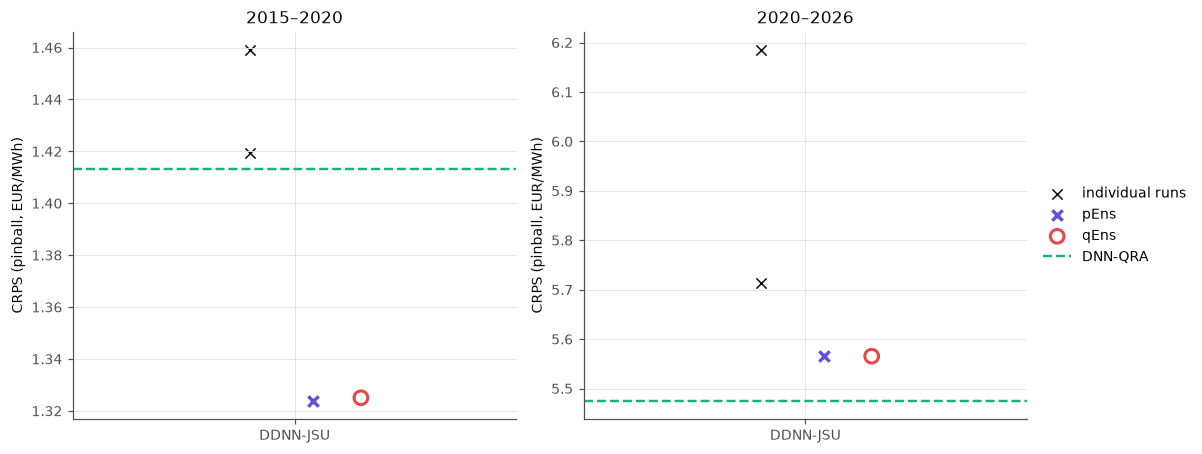

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, h in zip(axes, H):
    mt = H[h]["metrics_table"]["CRPS"]
    runs = [mt[f"DDNN-JSU-{r}"] for r in RUNS]
    ax.scatter([-0.12] * len(runs), runs, marker="x", s=45, color=INK, label="individual runs")
    ax.scatter([0.05], [mt["DDNN-JSU-pEns"]], marker="X", s=110, color="#6250d6",
               edgecolor="white", linewidth=1.5, label="pEns", zorder=3)
    ax.scatter([0.18], [mt["DDNN-JSU-qEns"]], marker="o", s=80, facecolor="none",
               edgecolor="#e34948", linewidth=2, label="qEns", zorder=3)
    for m, c in C_BENCH.items():
        if m in mt.index:
            ax.axhline(mt[m], color=c, lw=1.6, ls="-" if "LEAR" in m else "--", label=m)
    ax.set_xticks([0], ["DDNN-JSU"])
    ax.set_xlim(-0.6, 0.6)
    ax.set_title(LABEL[h])
    ax.set_ylabel("CRPS (pinball, EUR/MWh)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

**Diebold–Mariano p-values** (one-sided, daily L1-norm of the 24 hourly CRPS). A small p-value in
cell (row *i*, column *j*) means the **column** model's forecasts are significantly better than the
**row** model's. Colour: 0 % dark green → 5 % yellow → ≥ 10 % black. 6 × 6 without LEAR, 7 × 7 with LEAR-QRA.

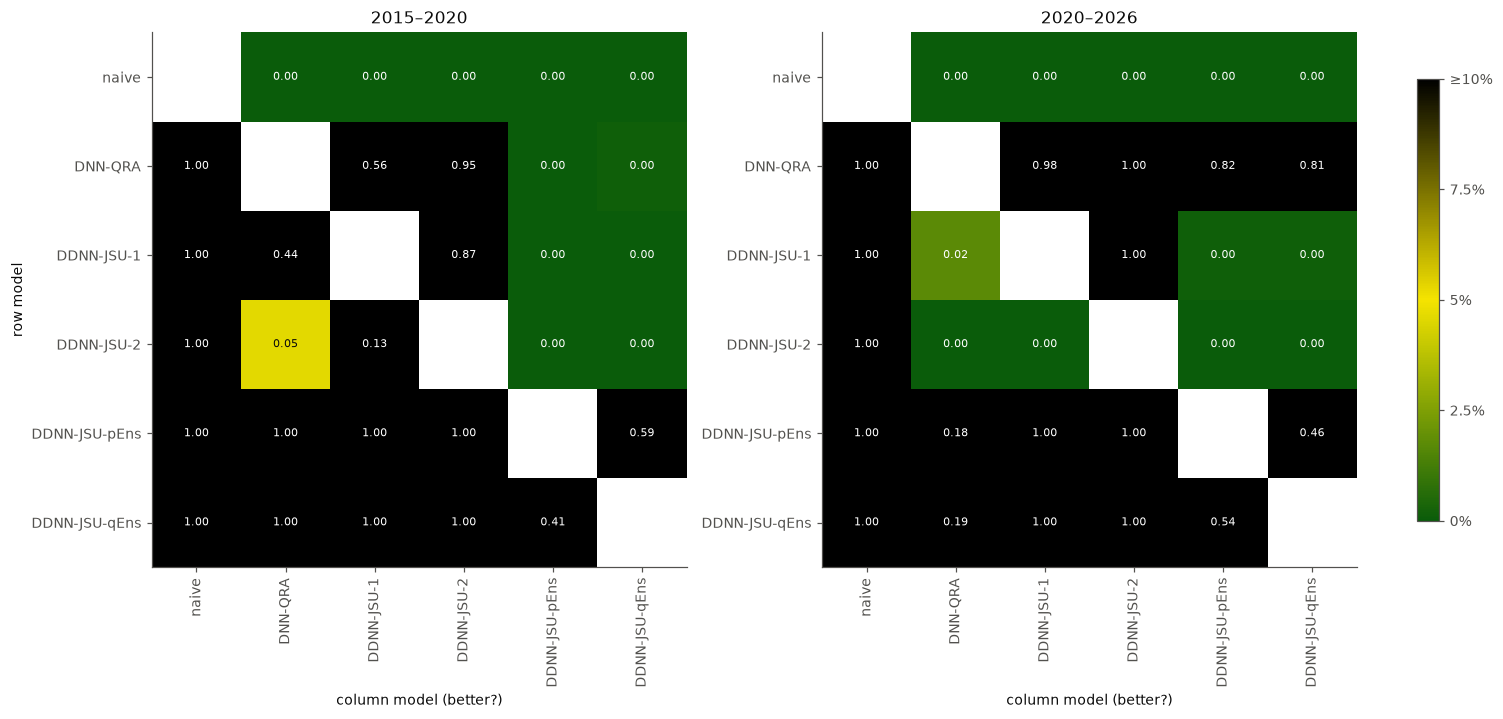

In [14]:
DM_CMAP = LinearSegmentedColormap.from_list("dm", [(0, "#0a5c0a"), (0.5, "#f5e400"), (1, "#000000")])
DM_CMAP.set_bad("#ffffff")
n = len(MODELS["dm"])
fig, axes = plt.subplots(1, 2, figsize=(4 + 1.6 * n, 1.5 + 0.8 * n), constrained_layout=True)
for ax, h in zip(axes, H):
    dm = H[h]["dm_test"]
    P = dm.to_numpy(dtype=float)
    im = ax.imshow(P, cmap=DM_CMAP, vmin=0, vmax=0.10)
    for i in range(n):
        for j in range(n):
            if np.isfinite(P[i, j]):
                ax.text(j, i, f"{P[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if (P[i, j] < 0.02 or P[i, j] > 0.08) else INK)
    ax.set_xticks(range(n), dm.columns, rotation=90)
    ax.set_yticks(range(n), dm.index)
    ax.grid(False)
    ax.set_title(LABEL[h])
    ax.set_xlabel("column model (better?)")
axes[0].set_ylabel("row model")
cb = fig.colorbar(im, ax=axes, shrink=0.8, ticks=[0, 0.025, 0.05, 0.075, 0.10])
cb.ax.set_yticklabels(["0%", "2.5%", "5%", "7.5%", "≥10%"])
plt.show()

In [15]:
# table view of the DM p-values
pd.concat({LABEL[h]: H[h]["dm_test"] for h in H}).style.format("{:.3f}", na_rep="–")

## 5. Prediction-interval strips (adaptation of Figure 4)

`plot_pi_week(horizon, start_date, days=7)` shows the realised price (black) with the 50 %, 90 %
and 98 % central prediction intervals (q25–q75, q05–q95, q01–q99) of DNN-QRA, DDNN-JSU-pEns and
DDNN-JSU-qEns (and LEAR-QRA when present), plus the day-ahead load and RES forecasts. Any window
inside the 554-day test period of the horizon can be used.

In [16]:
PI_MODELS = MODELS["pi"]
PI_BANDS = [(98, 0, 98), (90, 4, 94), (50, 24, 74)]       # (level, lower idx, upper idx) in the 99 quantiles

def plot_pi_week(horizon, start_date, days=7, models=PI_MODELS):
    res = H[horizon]
    dates = pd.DatetimeIndex(res["test_dates"])
    start = pd.Timestamp(start_date).normalize()
    if start not in dates or dates.get_loc(start) + days > len(dates):
        raise ValueError(f"{start.date()} + {days} d is outside the test period "
                         f"{dates[0].date()} -> {dates[-1].date()} of {horizon}")
    i0 = dates.get_loc(start)
    sl = slice(i0, i0 + days)
    idx = pd.date_range(start, periods=days * 24, freq="h")
    real = res["actuals"][sl].reshape(-1)
    fig, axes = plt.subplots(len(models) + 1, 1, figsize=(12, 2.1 * (len(models) + 1)), sharex=True)
    for ax, m in zip(axes, models):
        q = res["quantiles"][m][sl].reshape(-1, 99)
        for level, lo, hi in PI_BANDS:
            ax.fill_between(idx, q[:, lo], q[:, hi], color=PI_FILL[level], lw=0, step="mid", label=f"{level}% PI")
        ax.plot(idx, real, color=INK, lw=1.2, drawstyle="steps-mid", label="real")
        ax.set_ylabel("EUR/MWh")
        ax.set_title(m, loc="left", fontsize=9)
    ax = axes[-1]
    ext = frames[horizon].loc[idx]
    ax.plot(idx, ext["Load_DA_Forecast"] / 1e3, color="#2a78d6", label="Load forecast")
    ax.plot(idx, ext["Renewables_DA_Forecast"] / 1e3, color="#1baf7a", label="RES forecast")
    ax.set_ylabel("GWh")
    ax.set_title("External factors", loc="left", fontsize=9)
    ax.legend(loc="upper left", ncols=2)
    axes[0].legend(loc="upper left", ncols=4)
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b %Y"))
    fig.suptitle(f"{LABEL[horizon]}: {start.date()} → {(start + pd.Timedelta(days=days - 1)).date()}", x=0.01,
                 ha="left", fontsize=11)
    fig.tight_layout()
    return fig

def extreme_week(horizon, kind, days=7):
    # window of `days` test days centred on the day with the lowest ('negative') / highest ('spike') hourly price
    a = H[horizon]["actuals"]
    day = int(np.argmin(a.min(1)) if kind == "negative" else np.argmax(a.max(1)))
    start = int(np.clip(day - days // 2, 0, len(a) - days))
    return pd.Timestamp(H[horizon]["test_dates"][start])

### 5a. Paper benchmark week (sanity check): 2020-09-12 → 2020-09-18, 2015–2020 horizon

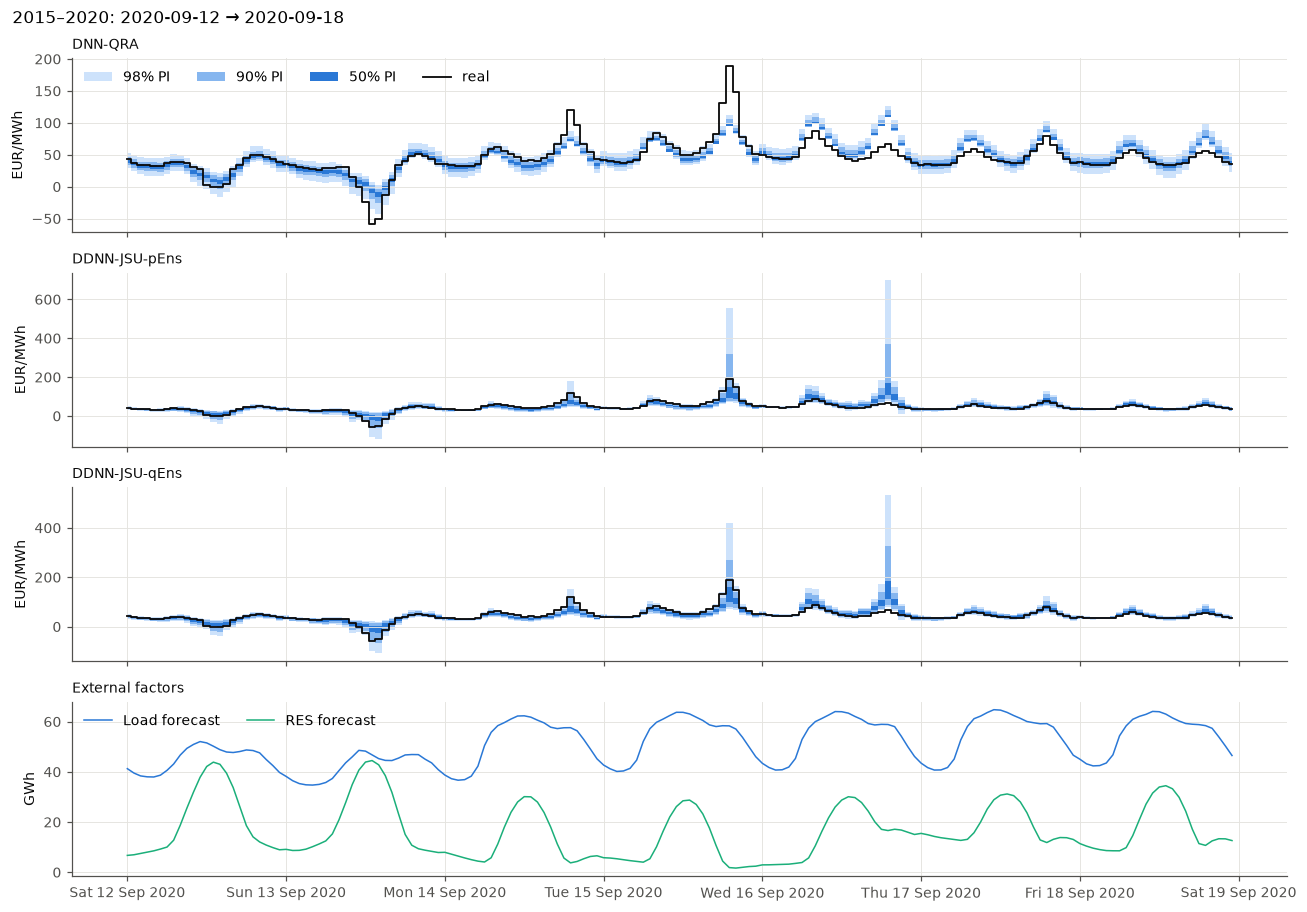

In [17]:
fig = plot_pi_week("2015-2020", "2020-09-12"); plt.show()

### 5b. 2020–2026: week around the most negative test-period price

start: 2026-04-28


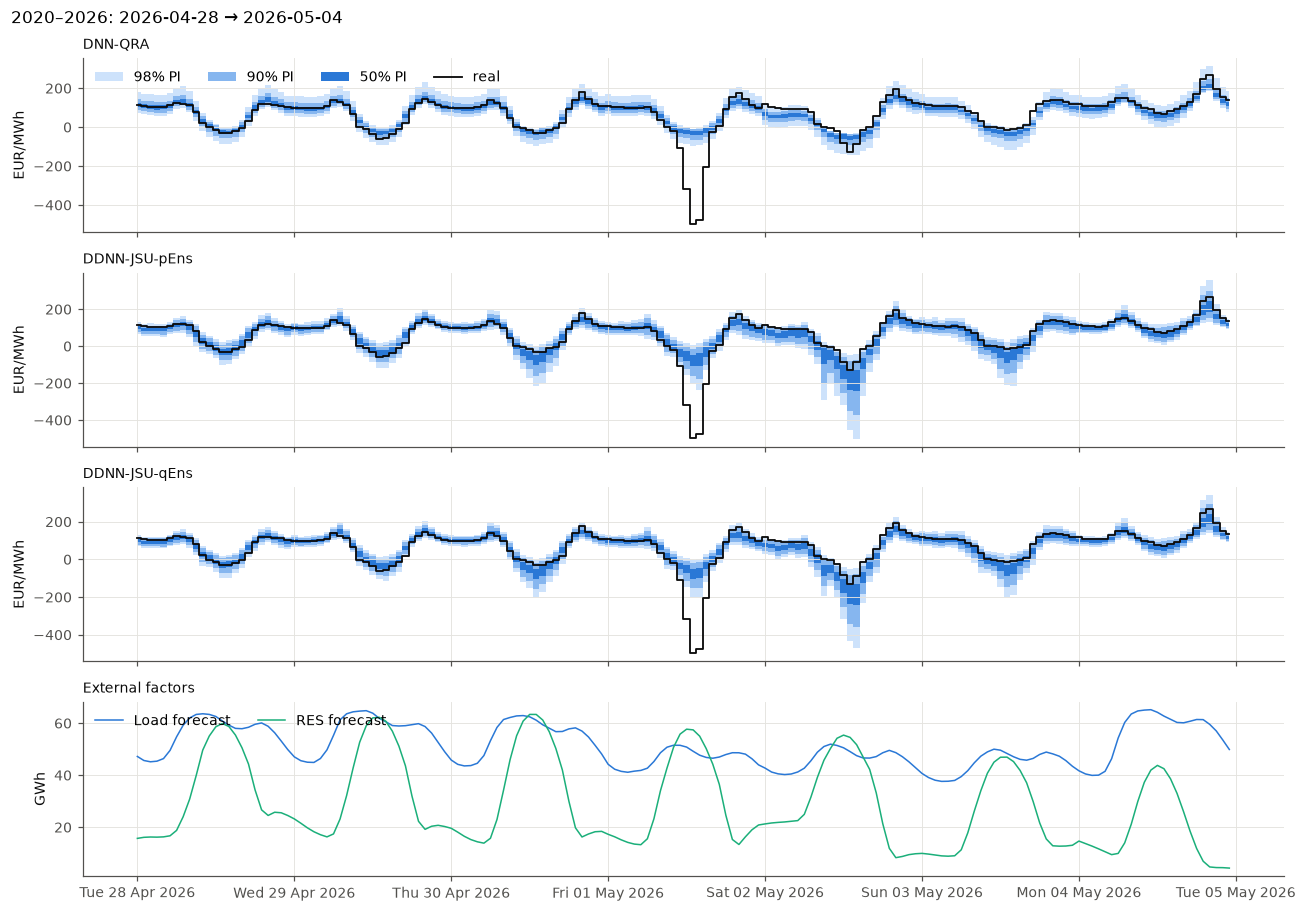

In [18]:
wk = extreme_week("2020-2026", "negative"); print("start:", wk.date())
fig = plot_pi_week("2020-2026", wk); plt.show()

### 5c. 2020–2026: week around the highest test-period price spike

start: 2026-09-11


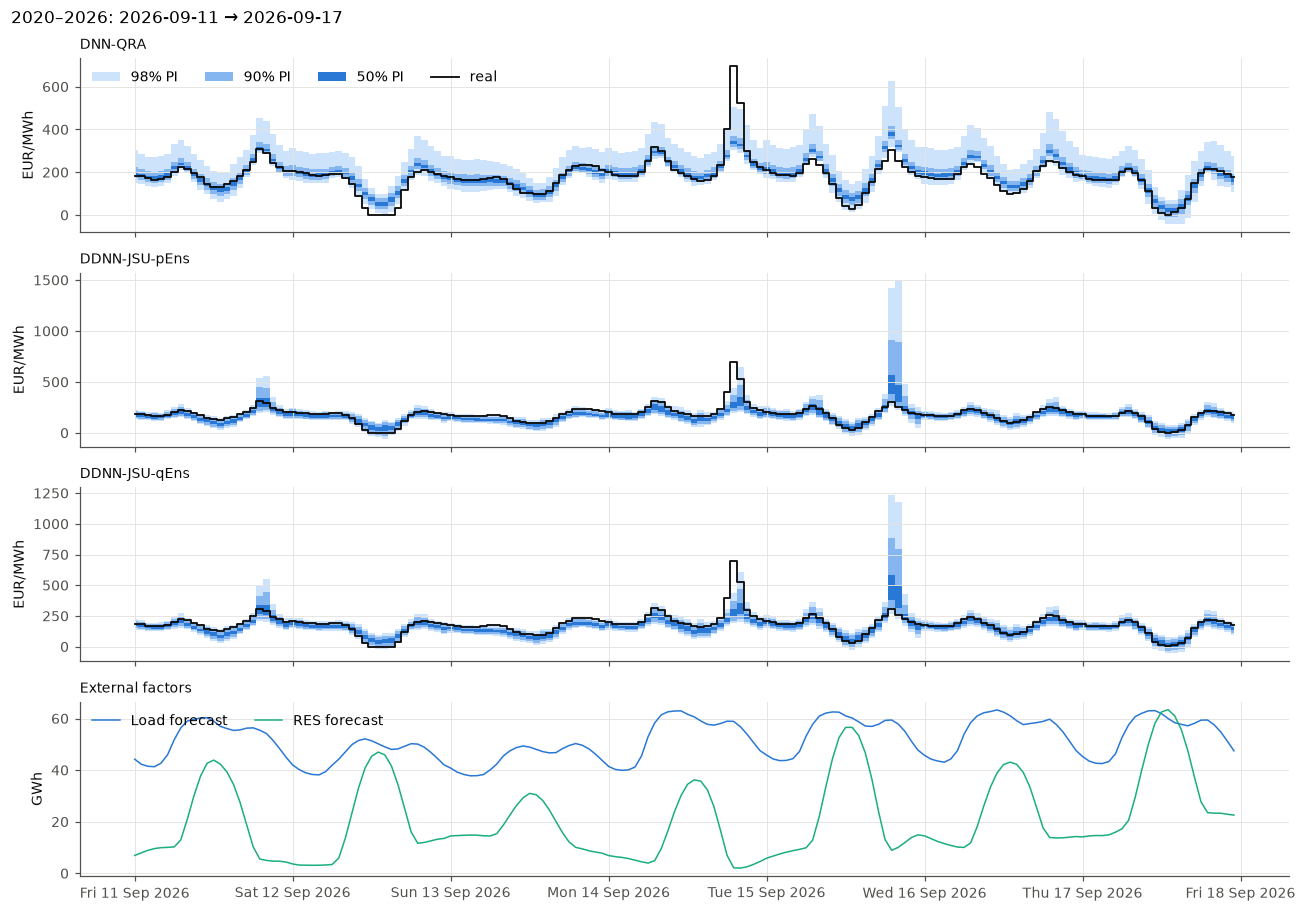

In [19]:
wk = extreme_week("2020-2026", "spike"); print("start:", wk.date())
fig = plot_pi_week("2020-2026", wk); plt.show()

### 5d. Custom window
Change `HORIZON`, `START` and `DAYS` and re-run the cell.

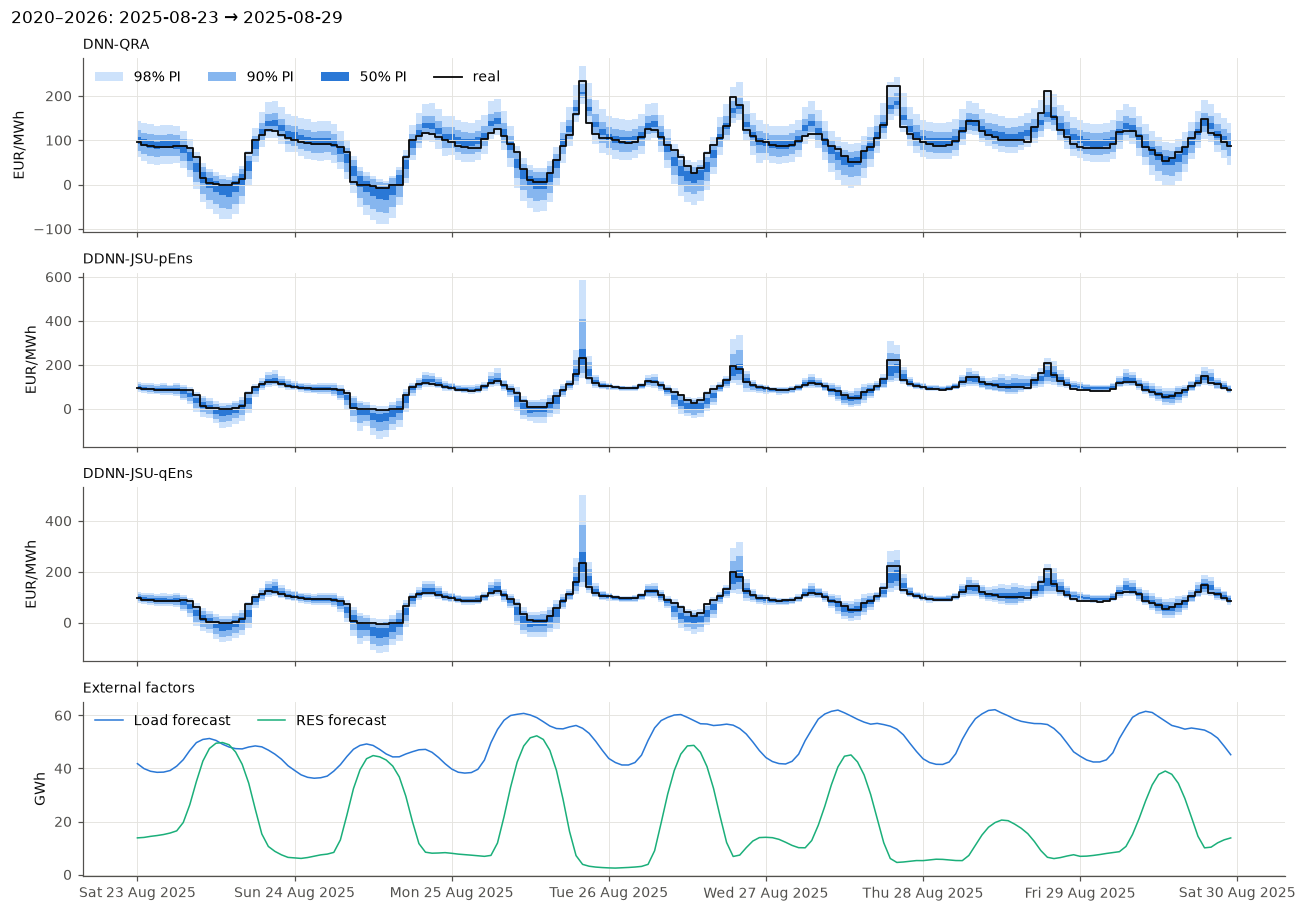

In [20]:
HORIZON, DAYS = "2020-2026", 7
START = pd.Timestamp(H[HORIZON]["test_dates"][100])     # e.g. "2025-12-22"
fig = plot_pi_week(HORIZON, START, DAYS); plt.show()

## Appendix A. Hyper-parameters re-used from the paper's Optuna studies

In [21]:
hp = H["2015-2020"]["selected_hyperparams"]
rows = []
for fam, runs in hp.items():
    for r, info in runs.items():
        p = info["params"]
        rows.append({"family": fam, "run": r, "trial": info["trial_number"], "val. loss": info["best_value"],
                     "neurons": f"{p['neurons_1']}/{p['neurons_2']}", "activations": f"{p['activation_1']}/{p['activation_2']}",
                     "learning rate": p["learning_rate"], "dropout": p.get("dropout_rate") if p.get("dropout") else 0.0,
                     "inputs": ", ".join(g for g, on in info["feature_mask"].items() if on)})
pd.DataFrame(rows).set_index(["family", "run"])

trial  val. loss  neurons        activations  learning rate  \
family   run                                                                
DNN      1     1496   3.612079  906/901  softplus/softplus       0.000176   
         2     2010   3.600974  912/619  softplus/softplus       0.000495   
DDNN-JSU 1     1926   2.929836  565/962      softplus/relu       0.000304   
         2     1990   2.975437   940/58            elu/elu       0.000316   

              dropout                                             inputs  
family   run                                                              
DNN      1        0.0  price_D-1, price_D-2, price_D-3, load_D, load_...  
         2        0.0  price_D-1, price_D-2, load_D, RES_D, RES_D-1, ...  
DDNN-JSU 1        0.0  price_D-1, load_D, load_D-1, load_D-7, RES_D, ...  
         2        0.0  price_D-1, price_D-2, price_D-7, load_D, load_...

## Appendix B. Flaws of the published code (fixed for both horizons) and run metadata

In [22]:
for k, v in META["original_code_flaws_fixed"].items():
    print(f"- {k}: {v}")
print()
for k, v in META["definitions"].items():
    print(f"- {k}: {v}")
print("\nsettings:", META["settings"])
print("versions:", META["versions"])

- weekday_index: X[d, 220] = data.index[d].weekday() uses hour d of the first day, not day d (should be data.index[d*24]); the weekday feature was essentially constant/wrong.
- brent_rolling_slice: lear.py / nn_rolling_pred.py read Brent from the full `data` frame instead of the rolling window `df`, i.e. Brent always came from the first days of the dataset.
- dow_encoding: a single integer weekday (0..6) was used instead of 7 one-hot day-of-week dummies as described in the paper; inputs now 227 instead of 221.

- MAE: from the median (q=0.50); point models: the point forecast
- RMSE: from the mean (DDNN: analytic; naive/QRA: mean of the 99 quantiles)
- CRPS: mean pinball loss over 99 percentiles, averaged over days and hours
- Rel_CRPS: 100 * (CRPS_ref - CRPS) / CRPS_ref, positive = better than reference
- Kupiec: per-hour unconditional coverage LR test at 5% for the 50% (q25-q75) and 90% (q05-q95) PI
- DM: one-sided DM on daily L1 norm of hourly CRPS; p[row, col] small => column bette

In [23]:
# every network fit (one row per re-fit): anchor = OOS day index of the fit, hit_cap = epoch limit reached
diag

,model,fit_date,anchor,epochs,best_epoch,best_val_loss,hit_cap,seconds,horizon
0,DNN-1,2018-12-27,0,303,253,3.210135,False,354.453191,2015–2020
1,DNN-1,2019-01-03,7,205,155,3.497345,False,259.107659,2015–2020
2,DNN-1,2019-01-10,14,210,160,3.211967,False,271.632342,2015–2020
3,DNN-1,2019-01-17,21,216,166,3.460261,False,293.271633,2015–2020
4,DNN-1,2019-01-24,28,206,156,3.424389,False,292.871727,2015–2020
...,...,...,...,...,...,...,...,...,...
739,DDNN-JSU-2,2026-10-22,707,296,246,4.093586,False,105.016804,2020–2026
740,DDNN-JSU-2,2026-10-29,714,278,228,4.132391,False,98.477501,2020–2026
741,DDNN-JSU-2,2026-11-05,721,388,338,4.092785,False,205.314154,2020–2026
742,DDNN-JSU-2,2026-11-12,728,324,274,4.143164,False,118.910248,2020–2026
